# DELIMITACIÓN DE LA PISCINA Y ELIMINACIÓN DE RUIDO — VISTA LATERAL (IL)

Juan David Hurtado Molano

Laura Sofía Salamanca Barrera

**Objetivo de la entrega.** Sobre la vista lateral desde fuera de la piscina (`data/images/IL`):

1. Trazar las corcheras como **rectas infinitas** con la transformada de Hough estándar (espacio $(\rho,\theta)$).
2. **Delimitar la piscina y cada carril con intersecciones** de esas rectas (entre sí y con los bordes de la imagen).
3. Usar la máscara de agua de `detector_color.py` para que el Canny que alimenta a Hough salga **limpio**.
4. **Quitar el ruido**: lo que está fuera de la piscina, el borde, el reloj de la transmisión y las propias corcheras, dejando la piscina lista para la siguiente entrega. *En esta entrega no se segmenta a los nadadores.*

**Pipeline**

```
imagen ─► máscara de agua (H 90-110, detector_color) ─► "no agua"
   │
   ├─► máscara de blanco ─► apertura horizontal ─► Canny ─► Hough ─► BORDE de la piscina (recta superior)
   │
   └─► (no agua ∪ color de corchera) ∩ debajo del borde ─► apertura horizontal ─► Canny LIMPIO
           ─► Hough (θ≈90°, paso 0.1°) ─► agrupar bordes ─► ajuste por mínimos cuadrados
           ─► validar (cobertura + color) ─► depurar por perspectiva ─► CORCHERAS
                                   │
  intersecciones (coordenadas homogéneas) ─► polígono de la piscina + polígono de cada carril
                                   │
  ruido = fuera de la piscina + borde + franjas de corcheras + restos + gráfico fijo ─► inpainting ─► IMAGEN SIN RUIDO
```

Todo lo que depende de la vista está en un solo diccionario (`PARAMS`), para poder llevar el mismo pipeline a ISL / ILP / IS cambiando parámetros y no código.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data" / "images").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import detector_color as dc  # máscara de agua de la primera entrega

VISTA = "IL"
RUTAS = sorted((ROOT / "data" / "images" / VISTA).glob("*.jpg"))
SALIDA = ROOT / "output" / "piscina" / VISTA
print(f"{len(RUTAS)} imágenes en data/images/{VISTA}")

plt.rcParams["figure.dpi"] = 90
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)


def mostrar(imagenes, titulos, cols=None, alto=4.2, cmap="gray"):
    cols = cols or len(imagenes)
    filas = int(np.ceil(len(imagenes) / cols))
    fig, ax = plt.subplots(filas, cols, figsize=(cols * alto * 16 / 9, filas * alto), squeeze=False)
    for a in ax.ravel():
        a.axis("off")
    for a, im, t in zip(ax.ravel(), imagenes, titulos):
        a.imshow(rgb(im) if im.ndim == 3 else im, cmap=cmap)
        a.set_title(t, fontsize=10)
    plt.tight_layout()
    plt.show()

20 imágenes en data/images/IL


## 0. Parámetros por vista

Los umbrales relativos (fracción del ancho `W`, del alto `H` o del alto de carril) hacen que el pipeline no dependa de la resolución. Lo específico de IL es la **orientación** (corcheras casi horizontales, $\theta \approx 90°$) y los **colores** de las corcheras de Río 2016.

In [2]:
PARAMS = {
    "IL": dict(
        theta_centro=90.0,     # dirección de las corcheras en Hough (90° = horizontal)
        theta_tol=12.0,        # ± grados alrededor de theta_centro
        theta_paso=0.1,        # resolución angular de Hough (grados)
        rho_paso=2,            # resolución de rho (px)
        largo_apertura=1 / 20, # largo del elemento estructurante horizontal (fracción de W)
        votos_corchera=0.25,   # votos mínimos en Hough (fracción de W)
        votos_borde=0.40,
        cobertura_min=0.45,    # fracción del ancho con soporte real a lo largo de la recta
        color_min=0.20,        # fracción de la franja con color de corchera
        ratio_perspectiva=0.6,
        blanco=((0, 0, 190), (180, 70, 255)),   # HSV del borde/canaleta
    )
}
P = PARAMS[VISTA]

# Colores de corchera (HSV de OpenCV: H 0-180). El azul de la corchera (H≈112) queda justo
# por encima del rango del agua (H 90-110): por eso se mide aparte.
COLORES_CORCHERA = {
    "amarilla": [((12, 90, 120), (35, 255, 255))],
    "azul":     [((108, 150, 60), (130, 255, 255))],
    "verde":    [((36, 80, 60), (90, 255, 255))],
    "roja":     [((0, 100, 60), (10, 255, 255)), ((165, 100, 60), (180, 255, 255))],
}

## 1. Exploración: ¿por qué no basta con Canny sobre la imagen?

Tres observaciones guiaron el diseño:

* **El oleaje mete bordes por todos lados.** Canny sobre el gris reacciona al *brillo*, y el brillo del agua cambia con cada ola y reflejo. La máscara de agua de `detector_color.py` se arma con el *tono* (H), que casi no cambia con un reflejo. Si Canny corre sobre una máscara binaria limpia, dentro del agua no hay textura que pueda volverse borde: solo quedan las fronteras agua / no-agua.
* **El cartel "Rio2016" tiene el mismo tono que el agua** (H≈105 vs H≈100). Ningún umbral de color separa la piscina del cartel, así que el límite superior de la piscina **no puede salir del color: tiene que salir de la geometría**. Entre el cartel y el agua hay siempre una línea blanca (borde/canaleta) que cruza todo el cuadro: esa es la recta superior de la piscina.
* **Las corcheras son estructuras horizontales largas** de colores que no son agua (amarillo, azul oscuro, verde, rojo). Un nadador o una salpicadura no son largos y horizontales a la vez.

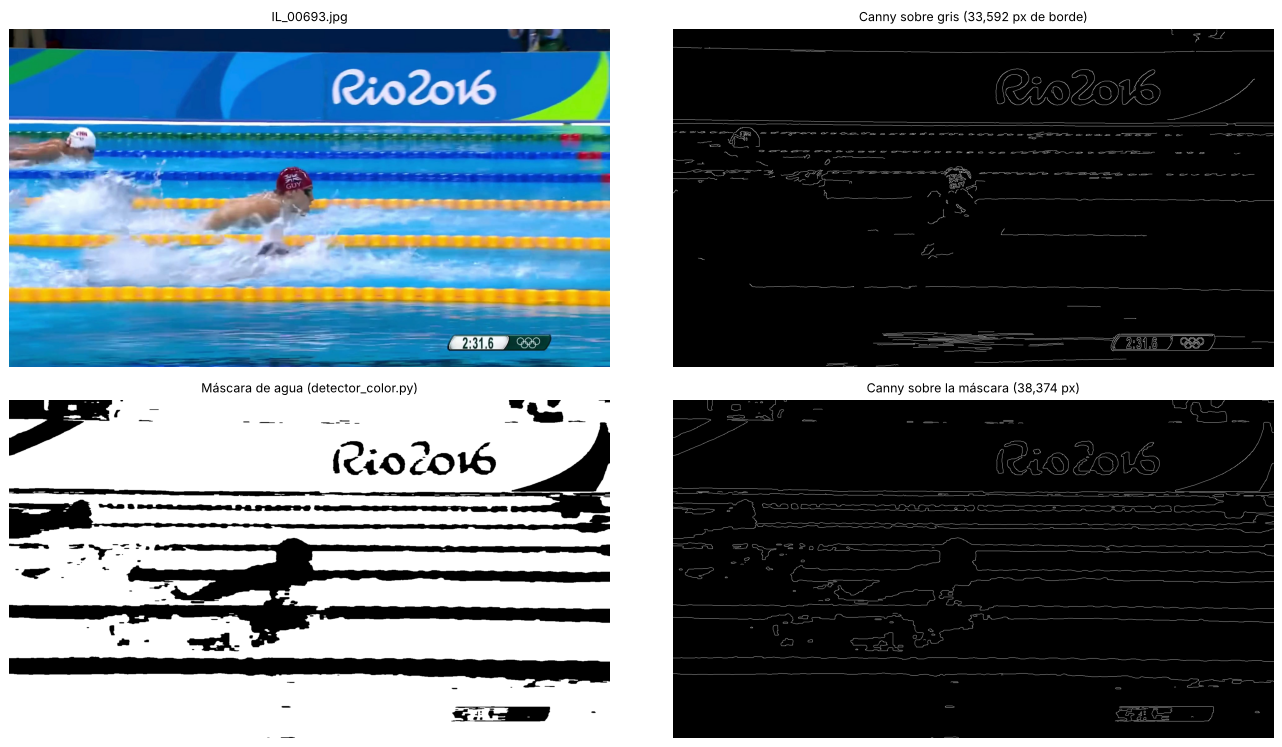

cartel      H mediana=105.0   S mediana=245.0   V mediana=203.0
agua        H mediana=100.0   S mediana=218.0   V mediana=184.0


In [3]:
im = cv2.imread(str(RUTAS[6]))
H, W = im.shape[:2]
hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)

gris = cv2.GaussianBlur(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), (5, 5), 0)
canny_gris = cv2.Canny(gris, 50, 150)
agua = dc.segmentar_agua(im, VISTA)
canny_mascara = cv2.Canny(agua, 50, 150)

mostrar([im, canny_gris, agua, canny_mascara],
        [RUTAS[6].name, f"Canny sobre gris ({(canny_gris > 0).sum():,} px de borde)",
         "Máscara de agua (detector_color.py)", f"Canny sobre la máscara ({(canny_mascara > 0).sum():,} px)"], cols=2)

def stats(nombre, y0, y1, x0, x1):
    r = hsv[y0:y1, x0:x1].reshape(-1, 3)
    print(f"{nombre:10s}  H mediana={np.median(r[:, 0]):5.1f}   S mediana={np.median(r[:, 1]):5.1f}   V mediana={np.median(r[:, 2]):5.1f}")
stats("cartel", 120, 260, 0, 900)
stats("agua", 900, 1000, 0, 1300)

## 2. Máscaras base

* **No agua** = complemento de la máscara de agua de `detector_color.py` (corcheras, nadadores, borde, público...).
* **Blanco** = poca saturación y mucho brillo (borde de la piscina, espuma, gorros blancos).
* **Color de corchera** = unión de los rangos HSV de amarilla/azul/verde/roja. Sirve para recuperar las corcheras lejanas, que son tan delgadas que la votación de `detector_color` a veces las parte.

**Apertura horizontal.** Con un elemento estructurante de 1 px de alto y `W/20` de largo, solo sobreviven los tramos que son horizontales y largos: corcheras y borde. Nadadores, espuma y público desaparecen casi por completo. Esta es la limpieza clave antes de Canny.

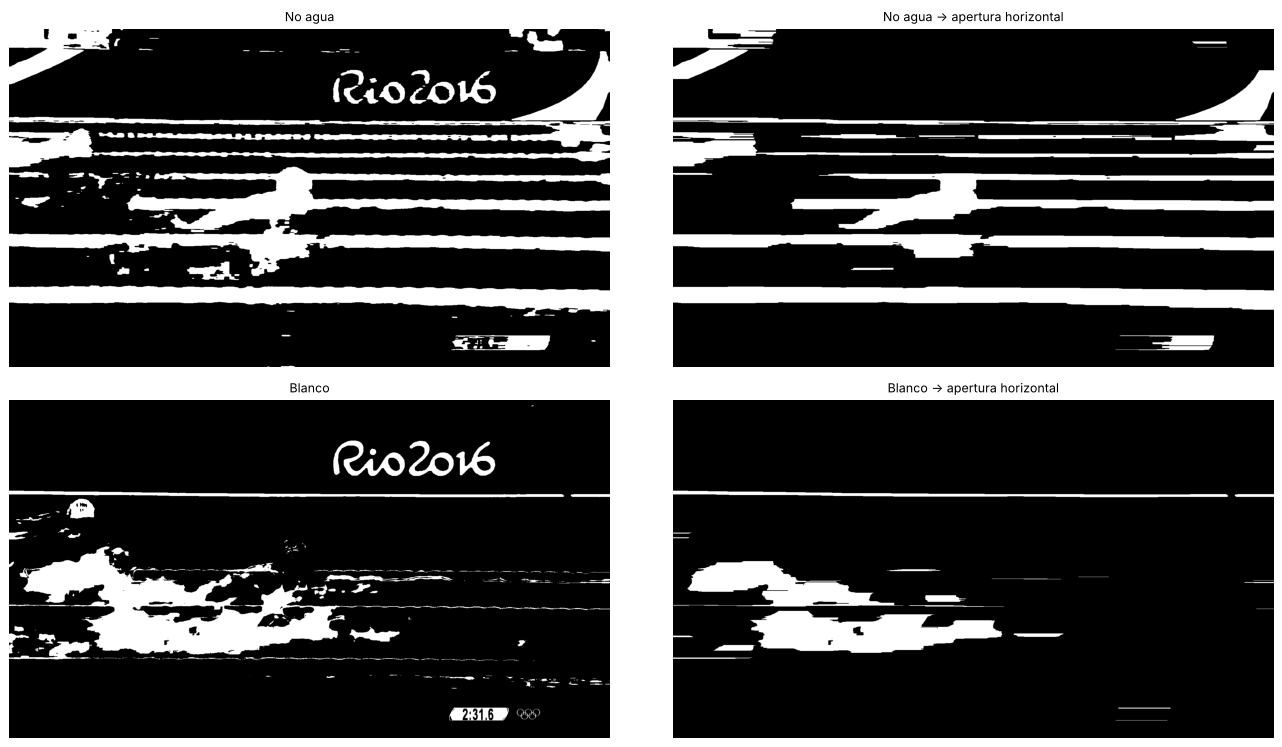

In [4]:
def mascaras_base(im, vista=VISTA):
    hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
    agua = dc.segmentar_agua(im, vista)
    blanco = cv2.inRange(hsv, *PARAMS[vista]["blanco"])
    return hsv, agua, cv2.bitwise_not(agua), blanco


def mascaras_color(hsv):
    out = {}
    for nombre, rangos in COLORES_CORCHERA.items():
        m = np.zeros(hsv.shape[:2], np.uint8)
        for lo, hi in rangos:
            m |= cv2.inRange(hsv, lo, hi)
        out[nombre] = m
    return out


def solo_horizontal(m, W, frac=None):
    largo = max(3, int(W * (frac or P["largo_apertura"])))
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (largo, 1)))


hsv, agua, no_agua, blanco = mascaras_base(im)
mostrar([no_agua, solo_horizontal(no_agua, W), blanco, solo_horizontal(blanco, W)],
        ["No agua", "No agua → apertura horizontal", "Blanco", "Blanco → apertura horizontal"], cols=2)

## 3. Geometría: rectas infinitas e intersecciones

Hough estándar (`cv2.HoughLines`, no la probabilística) devuelve cada recta como $(\rho, \theta)$: $x\cos\theta + y\sin\theta = \rho$. Esa recta es **infinita**, y se escribe en coordenadas homogéneas como el vector

$$\ell = (\cos\theta,\ \sin\theta,\ -\rho)$$

Con esa representación:

* un punto $p=(x,y,1)$ está en la recta si $\ell \cdot p = 0$;
* **la intersección de dos rectas es el producto cruz** $p = \ell_1 \times \ell_2$ (si $p_3 = 0$, son paralelas: se cortan en el infinito);
* los bordes de la imagen también son rectas: $x=0 \to (1,0,0)$, $x=W-1 \to (1,0,-(W-1))$, $y=H-1 \to (0,1,-(H-1))$.

Así, las esquinas de la piscina y de cada carril salen de cruzar rectas, sin casos especiales.

**Dos detalles que importan con imágenes de 1920 px:**

1. **Resolución angular fina (0.1°).** Con el paso típico de 1°, una corchera inclinada 0.5° reparte sus votos en ~17 celdas de $\rho$ a lo largo de 1920 px y no supera el umbral. Con 0.1°, cada corchera concentra sus votos en un pico.
2. **Refinamiento por mínimos cuadrados.** Hough da una buena recta *inicial*; luego se ajusta (`cv2.fitLine` con pérdida de Huber, robusta a nadadores que tapan la corchera) sobre los píxeles de la máscara cercanos a ella.

In [5]:
def recta_hough(rho, theta):
    return normalizar(np.array([np.cos(theta), np.sin(theta), -rho], float))


def normalizar(l):
    l = np.asarray(l, float) / np.hypot(l[0], l[1])
    return -l if l[1] < 0 else l          # orientación consistente: b > 0


def y_en(l, x):
    return -(l[0] * x + l[2]) / l[1]


def interseccion(l1, l2):
    p = np.cross(l1, l2)
    return None if abs(p[2]) < 1e-12 else p[:2] / p[2]


def bordes_imagen(W, H):
    return {"izq": np.array([1.0, 0, 0]), "der": np.array([1.0, 0, -(W - 1)]),
            "sup": np.array([0, 1.0, 0]), "inf": np.array([0, 1.0, -(H - 1)])}


def hough(bordes, W, frac_votos):
    t0, tol, paso = P["theta_centro"], P["theta_tol"], P["theta_paso"]
    L = cv2.HoughLines(bordes, P["rho_paso"], np.deg2rad(paso), int(frac_votos * W),
                       min_theta=np.deg2rad(t0 - tol), max_theta=np.deg2rad(t0 + tol))
    return [] if L is None else [recta_hough(r, t) for r, t in L[:, 0]]   # ordenadas por votos


def ajustar_recta(mascara, l0, d):
    # recta por mínimos cuadrados (Huber) con los píxeles de la máscara a menos de d px de l0
    ys, xs = np.nonzero(mascara)
    sel = np.abs(l0[0] * xs + l0[1] * ys + l0[2]) <= d
    if sel.sum() < 50:
        return None, None
    pts = np.c_[xs[sel], ys[sel]].astype(np.float32)
    vx, vy, x0, y0 = cv2.fitLine(pts, cv2.DIST_HUBER, 0, 0.01, 0.01).ravel()
    l = normalizar([-vy, vx, vy * x0 - vx * y0])
    r = l[0] * pts[:, 0] + l[1] * pts[:, 1] + l[2]
    lo, hi = np.percentile(r, [3, 97])
    l[2] -= (lo + hi) / 2                  # centrar la recta en el eje de la franja
    return l, hi - lo                      # recta y espesor de la franja


def muestrear(mascara, l, W, H, desplazamiento=0.0, paso=4):
    xs = np.arange(0, W, paso)
    ys = np.round(y_en(l, xs) + desplazamiento).astype(int)
    ok = (ys >= 0) & (ys < H)
    return mascara[ys[ok], xs[ok]] > 0


def franja(l, espesor, W, H, extra=0):
    m = np.zeros((H, W), np.uint8)
    cv2.line(m, (0, int(round(y_en(l, 0)))), (W - 1, int(round(y_en(l, W - 1)))), 255,
             max(1, int(round(espesor + 2 * extra))))
    return m


def debajo_de(l, W, H, margen=0):
    yy, xx = np.mgrid[0:H, 0:W]
    return (((l[0] * xx + l[1] * yy + l[2]) > margen) * 255).astype(np.uint8)


def dibujar_recta(img, l, color, grosor=2):
    W = img.shape[1]
    cv2.line(img, (0, int(round(y_en(l, 0)))), (W - 1, int(round(y_en(l, W - 1)))), color, grosor, cv2.LINE_AA)

## 4. Borde superior de la piscina

Máscara de blanco → apertura horizontal → Canny → Hough con umbral alto (40 % del ancho). Solo la línea del borde/canaleta cruza todo el cuadro siendo blanca; la espuma es blanca pero no es una línea larga. Se toma la recta con más votos y se refina por mínimos cuadrados.

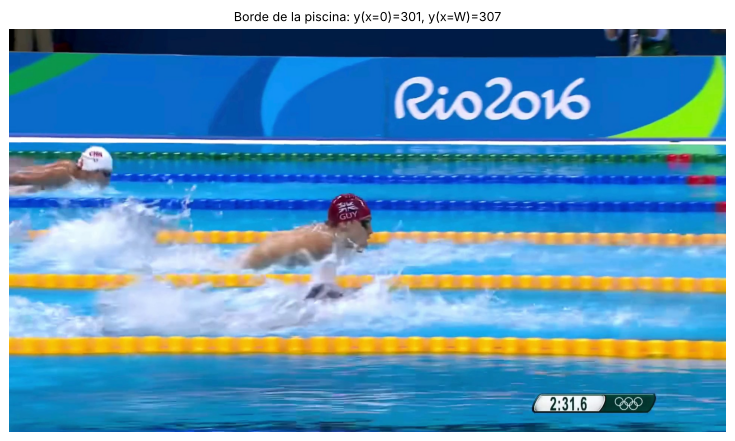

In [6]:
def detectar_borde(blanco, W, H):
    hz = solo_horizontal(blanco, W)
    L = hough(cv2.Canny(hz, 50, 150), W, P["votos_borde"])
    if not L:
        return None
    l, _ = ajustar_recta(hz, L[0], 8)
    return l if l is not None else L[0]


borde = detectar_borde(blanco, W, H)
vis = im.copy(); dibujar_recta(vis, borde, (255, 255, 255), 4)
mostrar([vis], [f"Borde de la piscina: y(x=0)={y_en(borde, 0):.0f}, y(x=W)={y_en(borde, W):.0f}"], alto=5)

## 5. Corcheras

1. **Máscara candidata** = (no agua ∪ color de corchera) **solo debajo del borde**: así el público y el cartel no aportan nada.
2. Apertura horizontal → **Canny limpio** → Hough ($\theta \in 90° \pm 12°$, paso 0.1°).
3. **Agrupar.** Cada corchera es una franja con dos bordes (arriba y abajo), así que Hough da al menos dos rectas por corchera. Dos rectas consecutivas son la misma corchera si la recta intermedia cae *dentro* de la máscara en al menos la mitad del ancho (entre dos corcheras distintas hay agua).
4. **Ajuste** por mínimos cuadrados de cada grupo → eje de la corchera + espesor.
5. **Validar** con dos medidas que no dependen de la imagen: *cobertura* (fracción del ancho con soporte real, ≥ 45 %) y *fracción de color de corchera* en la franja (≥ 20 %). Así se descartan las rectas que nacen de un brazo o de la espuma.
6. **Depurar por perspectiva.** Un carril se ve más ancho cuanto más cerca está de la cámara, así que la separación entre corcheras consecutivas **crece** hacia abajo. Una recta espuria parte un carril en dos y crea un hueco más angosto que el de arriba → se elimina la más débil de las dos.

In [7]:
def agrupar(lineas, mascara, W, H, llenado=0.5):
    if not lineas:
        return []
    lineas = sorted(lineas, key=lambda l: y_en(l, W / 2))
    grupos = [[lineas[0]]]
    for a, b in zip(lineas[:-1], lineas[1:]):
        dy = y_en(b, W / 2) - y_en(a, W / 2)
        misma = dy <= 3 or (dy <= 0.08 * H and muestrear(mascara, normalizar((a + b) / 2), W, H).mean() >= llenado)
        if misma:
            grupos[-1].append(b)
        else:
            grupos.append([b])
    return grupos


def detectar_corcheras(hsv, no_agua, borde, W, H, esp_borde=12):
    piscina = debajo_de(borde, W, H, esp_borde / 2 + 3)
    mcol = mascaras_color(hsv)
    color_corchera = np.zeros_like(no_agua)
    for v in mcol.values():
        color_corchera |= v
    hz = solo_horizontal((no_agua | color_corchera) & piscina, W)
    bordes = cv2.Canny(hz, 50, 150)
    lineas = hough(bordes, W, P["votos_corchera"])

    candidatas = []
    for g in agrupar(lineas, cv2.dilate(hz, np.ones((5, 1), np.uint8)), W, H):
        ys = [y_en(l, W / 2) for l in g]
        l, esp = ajustar_recta(hz, normalizar(np.mean(g, axis=0)), (max(ys) - min(ys)) / 2 + 4)
        if l is not None:
            candidatas.append((l, esp))

    def evaluar(l, esp):
        cobertura = muestrear(cv2.dilate(hz, np.ones((int(esp) + 3, 1), np.uint8)), l, W, H).mean()
        offs = np.linspace(-esp / 3, esp / 3, 5)
        perfil = {k: np.mean([muestrear(v, l, W, H, o).mean() for o in offs]) for k, v in mcol.items()}
        return dict(recta=l, espesor=float(esp), cobertura=float(cobertura),
                    color=max(perfil, key=perfil.get), frac_color=float(sum(perfil.values())),
                    y_centro=float(y_en(l, W / 2)),
                    valida=bool(cobertura >= P["cobertura_min"] and sum(perfil.values()) >= P["color_min"]))

    ev = sorted([evaluar(l, e) for l, e in candidatas], key=lambda c: c["y_centro"])
    validas = []
    for c in [c for c in ev if c["valida"]]:
        if validas:   # ejes casi superpuestos: dos bordes de la misma corchera que la curvatura del lente separó
            p = validas[-1]
            if c["y_centro"] - p["y_centro"] < max(c["espesor"], p["espesor"]) / 2 + 4:
                l2, e2 = ajustar_recta(hz, normalizar((c["recta"] + p["recta"]) / 2),
                                       (c["y_centro"] - p["y_centro"]) / 2 + max(c["espesor"], p["espesor"]) / 2)
                if l2 is not None:
                    validas[-1] = evaluar(l2, e2); validas[-1]["valida"] = True
                    continue
        validas.append(c)
    descartadas = [c for c in ev if not c["valida"]]
    return validas, descartadas, dict(hz=hz, bordes=bordes, lineas_hough=lineas)


def depurar_por_perspectiva(corcheras, ratio=None):
    ratio = ratio or P["ratio_perspectiva"]
    cs = sorted(corcheras, key=lambda c: c["y_centro"])
    q = lambda c: c["cobertura"] * c["frac_color"]
    eliminadas, cambio = [], True
    while cambio and len(cs) >= 3:
        cambio = False
        g = np.diff([c["y_centro"] for c in cs])
        for i in range(len(g)):
            a, b = cs[i], cs[i + 1]
            if i > 0:
                anomalo = g[i] < ratio * g[i - 1]
            else:   # primer carril: no hay uno arriba; además una de las dos debe ser claramente más débil
                anomalo = g[0] < ratio * g[1] and min(q(a), q(b)) < 0.5 * max(q(a), q(b))
            if anomalo:
                eliminadas.append(cs.pop(i if q(a) < q(b) else i + 1))
                cambio = True
                break
    return cs, eliminadas

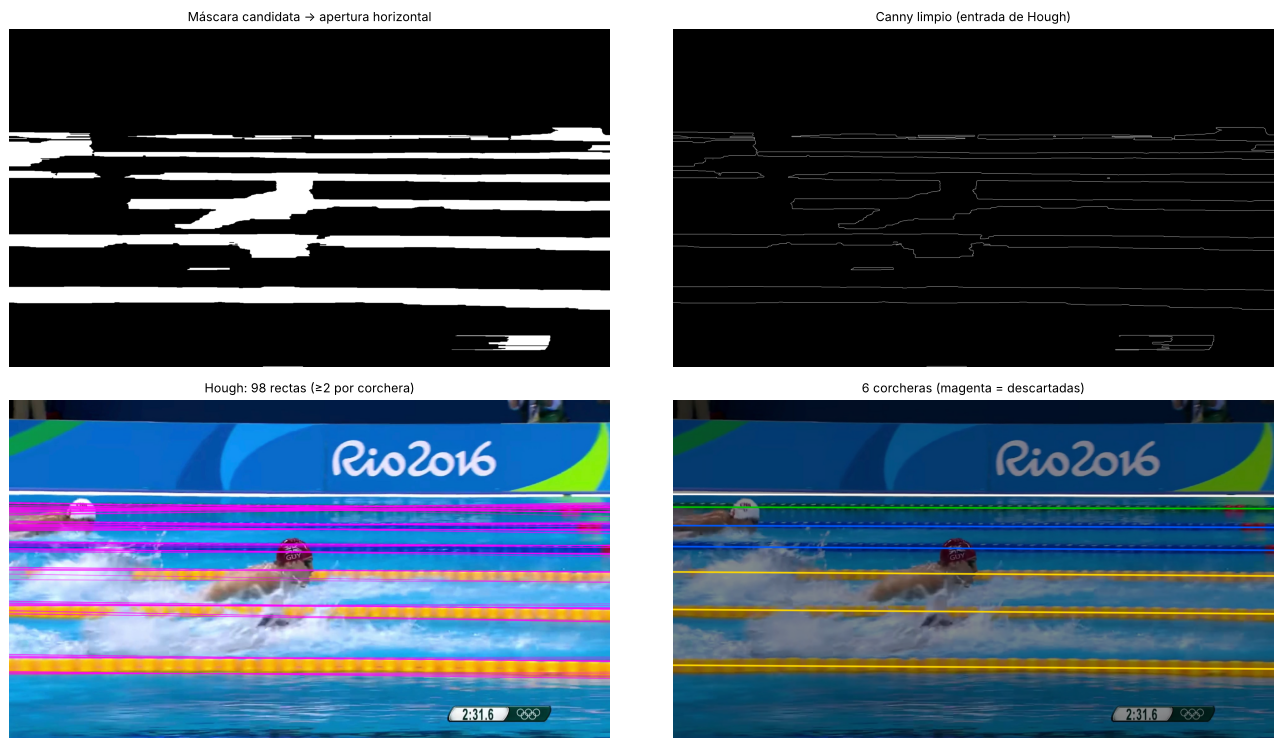

 y centro  ángulo  espesor  cobertura     color  frac
    344.8    0.15     19.7       0.94     verde  0.83
    403.8    0.19     19.7       1.00      azul  0.84
    473.6    0.36     23.3       0.96      azul  0.89
    555.4    0.37     34.7       0.80  amarilla  0.44
    675.9    0.43     31.5       1.00  amarilla  0.82
    853.1    0.34     48.3       1.00  amarilla  1.00


In [8]:
validas, descartadas, aux = detectar_corcheras(hsv, no_agua, borde, W, H)
corcheras, eliminadas = depurar_por_perspectiva(validas)

BGR = {"amarilla": (0, 215, 255), "azul": (255, 90, 0), "verde": (0, 200, 0), "roja": (0, 0, 255)}
hough_vis = im.copy()
for l in aux["lineas_hough"]:
    dibujar_recta(hough_vis, l, (255, 0, 255), 1)
res = (im * 0.55).astype(np.uint8)
dibujar_recta(res, borde, (255, 255, 255), 4)
for c in descartadas + eliminadas:
    dibujar_recta(res, c["recta"], (255, 0, 255), 1)
for c in corcheras:
    dibujar_recta(res, c["recta"], BGR[c["color"]], 3)

mostrar([aux["hz"], aux["bordes"], hough_vis, res],
        ["Máscara candidata → apertura horizontal", "Canny limpio (entrada de Hough)",
         f"Hough: {len(aux['lineas_hough'])} rectas (≥2 por corchera)",
         f"{len(corcheras)} corcheras (magenta = descartadas)"], cols=2)

print(f"{'y centro':>9} {'ángulo':>7} {'espesor':>8} {'cobertura':>10} {'color':>9} {'frac':>5}")
for c in corcheras:
    ang = np.degrees(np.arctan2(-c['recta'][0], c['recta'][1]))
    print(f"{c['y_centro']:9.1f} {ang:7.2f} {c['espesor']:8.1f} {c['cobertura']:10.2f} {c['color']:>9} {c['frac_color']:5.2f}")

### ¿Cuánto aporta la limpieza? Comparación directa

Mismo Hough (mismos umbrales) sobre dos entradas: el Canny del gris y el Canny limpio de la sección anterior. Se cuentan las rectas que caen fuera de la piscina (sobre el borde) y las que no coinciden con ninguna corchera validada. También se compara el paso angular de 1° contra 0.1°.

Canny gris    paso 1.0°:  12 rectas | fuera de la piscina:   2 | sobre corchera:   4 | otras (espuma, nadador):   6 | corcheras halladas: 3/6
Canny gris    paso 0.1°:  87 rectas | fuera de la piscina:  22 | sobre corchera:  28 | otras (espuma, nadador):  37 | corcheras halladas: 5/6
Canny limpio  paso 1.0°:  12 rectas | fuera de la piscina:   0 | sobre corchera:  12 | otras (espuma, nadador):   0 | corcheras halladas: 5/6
Canny limpio  paso 0.1°:  98 rectas | fuera de la piscina:   0 | sobre corchera:  97 | otras (espuma, nadador):   1 | corcheras halladas: 6/6


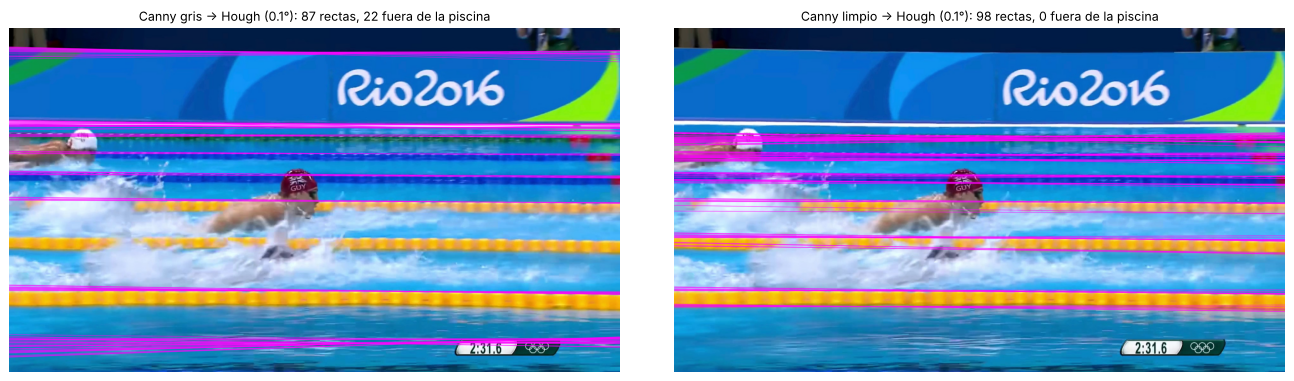

In [9]:
def resumen_hough(bordes_in, paso_deg):
    t0, tol = P["theta_centro"], P["theta_tol"]
    L = cv2.HoughLines(bordes_in, P["rho_paso"], np.deg2rad(paso_deg), int(P["votos_corchera"] * W),
                       min_theta=np.deg2rad(t0 - tol), max_theta=np.deg2rad(t0 + tol))
    L = [] if L is None else [recta_hough(r, t) for r, t in L[:, 0]]
    fuera = sum(y_en(l, W / 2) < y_en(borde, W / 2) for l in L)
    cerca = lambda l, c: abs(y_en(l, W / 2) - c["y_centro"]) <= c["espesor"] / 2 + 6
    en_corchera = sum(any(cerca(l, c) for c in corcheras) for l in L)
    encontradas = sum(any(cerca(l, c) for l in L) for c in corcheras)
    return L, fuera, en_corchera, encontradas

comparacion = []
for nombre, b in [("Canny gris", canny_gris), ("Canny limpio", aux["bordes"])]:
    for paso in (1.0, 0.1):
        L, fuera, ok, enc = resumen_hough(b, paso)
        comparacion.append((nombre, paso, L, fuera, ok))
        print(f"{nombre:13s} paso {paso:>3}°: {len(L):3d} rectas | fuera de la piscina: {fuera:3d} | "
              f"sobre corchera: {ok:3d} | otras (espuma, nadador): {len(L) - fuera - ok:3d} | "
              f"corcheras halladas: {enc}/{len(corcheras)}")

paneles = []
for nombre, paso, L, fuera, ok in comparacion:
    if paso != 0.1:
        continue
    v = im.copy()
    for l in L:
        dibujar_recta(v, l, (255, 0, 255), 1)
    paneles.append((v, f"{nombre} → Hough (0.1°): {len(L)} rectas, {fuera} fuera de la piscina"))
mostrar([p for p, _ in paneles], [t for _, t in paneles], cols=2)

## 6. Delimitación por intersecciones

* **Piscina**: el borde superior cortado con los bordes izquierdo y derecho de la imagen da las dos esquinas de arriba. En IL la piscina continúa por debajo del cuadro, así que el límite inferior es el borde inferior de la imagen.
* **Carriles**: cada par de rectas consecutivas (borde→1ª corchera, corchera *i*→corchera *i+1*, última corchera→borde inferior) cortadas con los bordes laterales da un cuadrilátero.
* **Punto de fuga**: todas las corcheras son paralelas en el mundo, así que en la imagen deberían cortarse en un mismo punto. Se estima por mínimos cuadrados (vector singular de la matriz de rectas) y sirve de chequeo: en IL la cámara mira casi de frente a las corcheras, así que el punto de fuga cae muy lejos (casi paralelas).

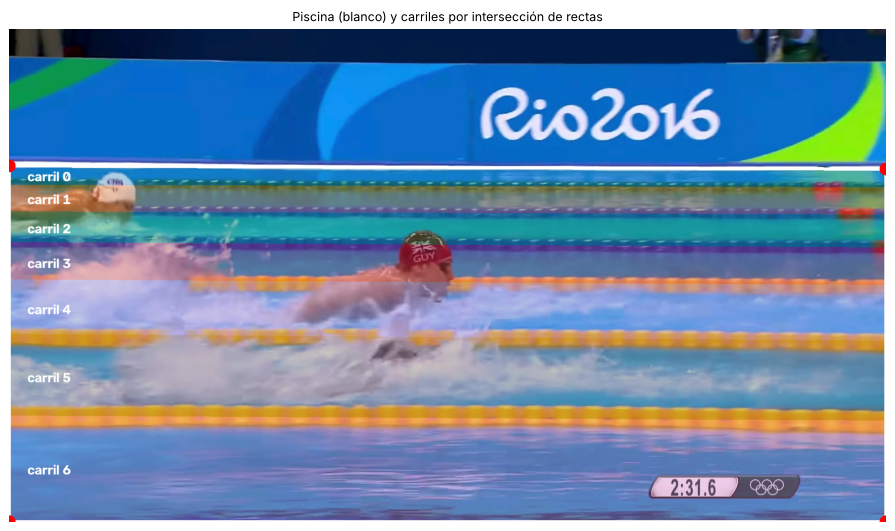

Esquinas de la piscina (x, y):
 [[  -0.   300.9]
 [1919.   307.2]
 [1919.  1079. ]
 [  -0.  1079. ]]
Punto de fuga de las corcheras: [-137697.    -187.] → prácticamente paralelas


In [10]:
def poligono_piscina(borde, W, H):
    B = bordes_imagen(W, H)
    return np.array([interseccion(borde, B["izq"]), interseccion(borde, B["der"]),
                     interseccion(B["inf"], B["der"]), interseccion(B["inf"], B["izq"])], np.float32)


def poligonos_carriles(borde, corcheras, W, H):
    B = bordes_imagen(W, H)
    rectas = [borde] + [c["recta"] for c in corcheras] + [B["inf"]]
    return [np.array([interseccion(a, B["izq"]), interseccion(a, B["der"]),
                      interseccion(b, B["der"]), interseccion(b, B["izq"])], np.float32)
            for a, b in zip(rectas[:-1], rectas[1:])]


def punto_de_fuga(rectas):
    L = np.array([normalizar(l) for l in rectas])
    p = np.linalg.svd(L)[2][-1]
    return None if abs(p[2]) < 1e-12 else p[:2] / p[2]


esquinas = poligono_piscina(borde, W, H)
carriles = poligonos_carriles(borde, corcheras, W, H)
pf = punto_de_fuga([borde] + [c["recta"] for c in corcheras])

vis = im.copy(); capa = im.copy()
paleta = plt.cm.tab10(np.arange(10))[:, :3][:, ::-1] * 255
for k, pol in enumerate(carriles):
    cv2.fillPoly(capa, [pol.astype(np.int32)], paleta[k % 10].tolist())
vis = cv2.addWeighted(capa, 0.35, vis, 0.65, 0)
cv2.polylines(vis, [esquinas.astype(np.int32)], True, (255, 255, 255), 5)
for k, pol in enumerate(carriles):
    cx, cy = pol[:, 0].mean(), pol[:, 1].mean()
    cv2.putText(vis, f"carril {k}", (40, int(cy) + 10), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 3)
for x, y in esquinas:
    cv2.circle(vis, (int(x), int(y)), 14, (0, 0, 255), -1)
mostrar([vis], ["Piscina (blanco) y carriles por intersección de rectas"], alto=6)

print("Esquinas de la piscina (x, y):\n", np.round(esquinas, 1))
print("Punto de fuga de las corcheras:", None if pf is None else np.round(pf, 0),
      "→ prácticamente paralelas" if pf is None or abs(pf[0]) > 20 * W else "")

## 7. Quitar el ruido

Con la piscina y las corcheras ya reconocidas, el ruido queda definido **por geometría**, no por color de cada píxel:

| Ruido | Cómo se identifica |
|---|---|
| Fuera de la piscina (público, cartel, jueces) | polígono de la piscina (intersecciones) |
| Borde / canaleta | franja alrededor de la recta superior |
| Corcheras | franja alrededor de cada recta, con el espesor medido en la sección 5 |
| Restos de corchera fuera de la franja (curvatura del lente, tramos rojos de los extremos) | color de corchera + estructura horizontal larga |
| Reloj y logo de la transmisión | **persistencia temporal**: lo que es "no agua" en ≥ 90 % de los cuadros no se mueve con la cámara, así que es un gráfico sobreimpreso |

Ese ruido se **elimina de la imagen**: lo de fuera de la piscina y el borde se ponen en negro, y lo de adentro (corcheras, restos, reloj) se rellena con *inpainting* (Telea), que propaga el agua de alrededor. El resultado es la piscina sin corcheras, lista para la siguiente entrega. En esta entrega **no se segmenta a los nadadores**: quedan en la imagen tal como están.

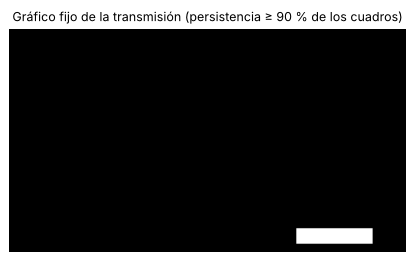

In [11]:
def mascara_estatica(rutas, umbral=0.9, vista=VISTA):
    acc = None
    for r in rutas:
        no = dc.segmentar_agua(cv2.imread(str(r)), vista) == 0
        acc = no.astype(np.float32) if acc is None else acc + no
    persistente = (((acc / len(rutas)) >= umbral) * 255).astype(np.uint8)
    persistente = cv2.dilate(persistente, np.ones((31, 61), np.uint8))   # une las piezas del gráfico
    n, _, st, _ = cv2.connectedComponentsWithStats(persistente)
    out = np.zeros_like(persistente)
    for x, y, w, h, a in st[1:]:
        if a >= 2000:
            cv2.rectangle(out, (x, y), (x + w, y + h), 255, -1)
    return out


ESTATICA = mascara_estatica(RUTAS)
mostrar([ESTATICA], ["Gráfico fijo de la transmisión (persistencia ≥ 90 % de los cuadros)"], alto=3)

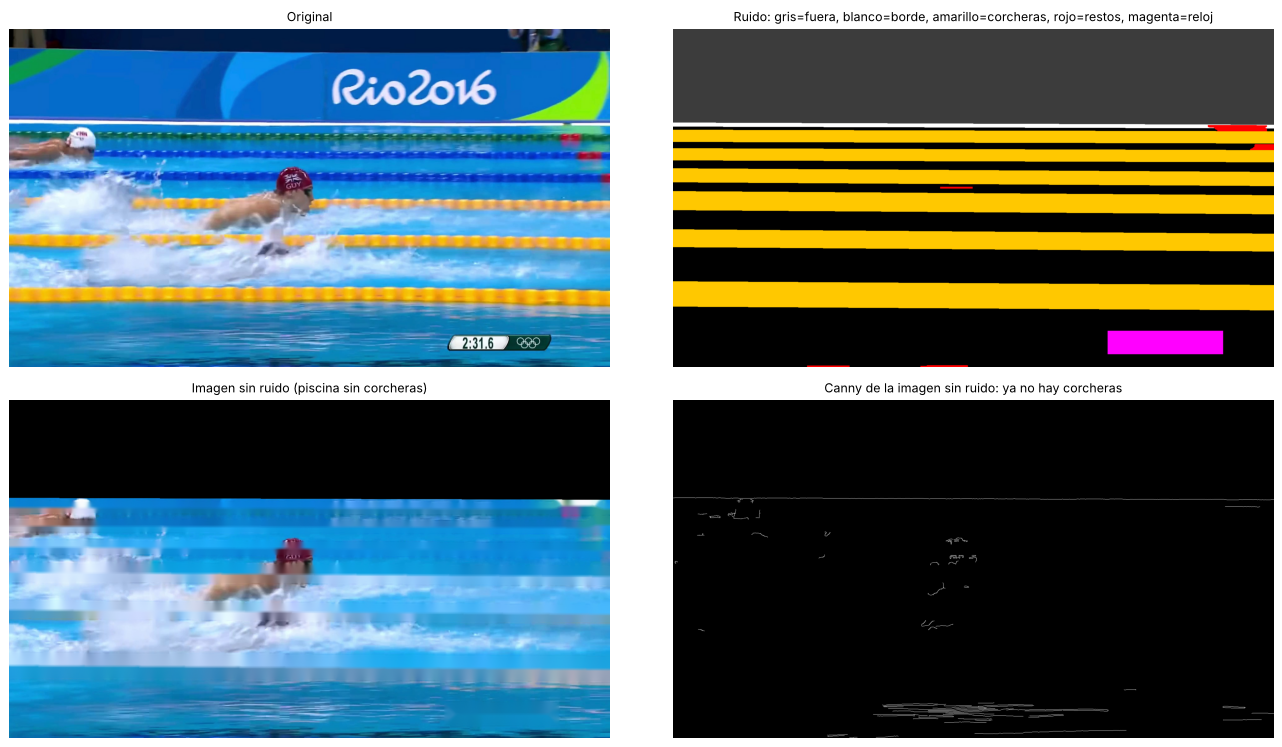

In [12]:
def mascaras_ruido(hsv, borde, corcheras, estatica, W, H, esp_borde=14):
    piscina = np.zeros((H, W), np.uint8)
    cv2.fillConvexPoly(piscina, poligono_piscina(borde, W, H).astype(np.int32), 255)
    bandas = np.zeros((H, W), np.uint8)
    for c in corcheras:
        bandas |= franja(c["recta"], c["espesor"], W, H, 4 + 0.25 * c["espesor"])
    color_c = np.zeros((H, W), np.uint8)
    for v in mascaras_color(hsv).values():
        color_c |= v
    restos = solo_horizontal(cv2.morphologyEx(color_c, cv2.MORPH_CLOSE, np.ones((1, 9), np.uint8)), W)
    restos = cv2.dilate(restos, np.ones((5, 9), np.uint8))
    capas = dict(fuera=cv2.bitwise_not(piscina),
                 borde=franja(borde, esp_borde, W, H, 4) & piscina,
                 corcheras=bandas & piscina,
                 restos=restos & piscina & ~bandas,
                 grafico=(estatica if estatica is not None else np.zeros_like(piscina)) & piscina)
    return piscina, capas


def quitar_ruido(im, piscina, capas, escala=0.5, radio=5):
    # inpainting a media resolución (rápido) y se pegan solo los píxeles de ruido
    H, W = im.shape[:2]
    adentro = capas["corcheras"] | capas["restos"] | capas["grafico"]
    chica = cv2.resize(im, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
    m = cv2.resize(adentro, (chica.shape[1], chica.shape[0]), interpolation=cv2.INTER_NEAREST)
    relleno = cv2.resize(cv2.inpaint(chica, m, radio, cv2.INPAINT_TELEA), (W, H))
    limpia = im.copy()
    limpia[adentro > 0] = relleno[adentro > 0]
    limpia[(piscina == 0) | (capas["borde"] > 0)] = 0   # el borde no es agua: se descarta como lo de afuera
    return limpia


COLORES_RUIDO = [("fuera", (60, 60, 60)), ("borde", (255, 255, 255)), ("corcheras", (0, 200, 255)),
                 ("restos", (0, 0, 255)), ("grafico", (255, 0, 255))]

def pintar_ruido(capas, forma):
    out = np.zeros(forma, np.uint8)
    for nombre, col in COLORES_RUIDO:
        out[capas[nombre] > 0] = col
    return out


piscina_m, capas = mascaras_ruido(hsv, borde, corcheras, ESTATICA, W, H)
limpia = quitar_ruido(im, piscina_m, capas)
mostrar([im, pintar_ruido(capas, im.shape), limpia, cv2.Canny(cv2.GaussianBlur(cv2.cvtColor(limpia, cv2.COLOR_BGR2GRAY), (5, 5), 0), 50, 150)],
        ["Original", "Ruido: gris=fuera, blanco=borde, amarillo=corcheras, rojo=restos, magenta=reloj",
         "Imagen sin ruido (piscina sin corcheras)", "Canny de la imagen sin ruido: ya no hay corcheras"], cols=2)

### Verificación: ¿quedan corcheras después de quitar el ruido?

Si la limpieza funcionó, al correr el **mismo** detector de corcheras sobre la imagen sin ruido no debería encontrar ninguna recta horizontal larga dentro de la piscina.

In [13]:
def rectas_restantes(img_limpia, borde, W, H, margen=25):
    # se ignora la frontera artificial negro/agua que deja el recorte en el borde
    hsv_l = cv2.cvtColor(img_limpia, cv2.COLOR_BGR2HSV)
    no_l = cv2.bitwise_not(dc.segmentar_agua(img_limpia, VISTA))
    _, _, aux_l = detectar_corcheras(hsv_l, no_l, borde, W, H)
    return [l for l in aux_l["lineas_hough"] if y_en(l, W / 2) > y_en(borde, W / 2) + margen]

antes = len(aux["lineas_hough"])
despues = len(rectas_restantes(limpia, borde, W, H))
print(f"Rectas de Hough dentro de la piscina — antes: {antes} | después de quitar el ruido: {despues}")

Rectas de Hough dentro de la piscina — antes: 98 | después de quitar el ruido: 0


## 8. Pipeline completo y resultados en todas las imágenes IL

Una sola función recibe la imagen y corre todo el proceso (borde, corcheras, piscina, ruido). El **resultado final** son solo las corcheras reconocidas, dibujadas con su color, y se guarda en `output/piscina/IL/*_corcheras.jpg`.

In [14]:
def procesar(im, estatica=None):
    H, W = im.shape[:2]
    hsv, agua, no_agua, blanco = mascaras_base(im)
    borde = detectar_borde(blanco, W, H)
    if borde is None:
        raise RuntimeError("No se encontró el borde de la piscina")
    validas, descartadas, aux = detectar_corcheras(hsv, no_agua, borde, W, H)
    corcheras, eliminadas = depurar_por_perspectiva(validas)
    piscina_m, capas = mascaras_ruido(hsv, borde, corcheras, estatica, W, H)
    limpia = quitar_ruido(im, piscina_m, capas)
    ruido = np.zeros((H, W), np.uint8)
    for c in capas.values():
        ruido |= c
    return dict(borde=borde, corcheras=corcheras, descartadas=descartadas + eliminadas,
                piscina=poligono_piscina(borde, W, H), carriles=poligonos_carriles(borde, corcheras, W, H),
                capas=capas, ruido=ruido, limpia=limpia, canny=aux["bordes"],
                rectas_restantes=len(rectas_restantes(limpia, borde, W, H)))


def dibujar(im, r):
    # resultado final: solo las corcheras reconocidas (sin polígono de piscina ni capas de ruido)
    vis = (im * 0.55).astype(np.uint8)
    for c in r["corcheras"]:
        dibujar_recta(vis, c["recta"], BGR[c["color"]], 3)
    return vis


SALIDA.mkdir(parents=True, exist_ok=True)
resultados, vistas = {}, []
for ruta in RUTAS:
    img = cv2.imread(str(ruta))
    r = procesar(img, ESTATICA)
    resultados[ruta.name] = r
    vis = dibujar(img, r)
    cv2.imwrite(str(SALIDA / f"{ruta.stem}_corcheras.jpg"), vis)
    vistas.append((vis, ruta.stem, len(r["corcheras"])))
    print(f"{ruta.stem}  {len(r['corcheras'])} corcheras en y = {[round(c['y_centro']) for c in r['corcheras']]}"
          f"  | rectas que quedan tras limpiar: {r['rectas_restantes']}")

IL_00099  6 corcheras en y = [384, 419, 471, 552, 670, 845]  | rectas que quedan tras limpiar: 0


IL_00198  8 corcheras en y = [417, 448, 485, 534, 599, 697, 836, 1059]  | rectas que quedan tras limpiar: 0


IL_00297  7 corcheras en y = [504, 533, 566, 613, 681, 784, 959]  | rectas que quedan tras limpiar: 0


IL_00396  7 corcheras en y = [445, 472, 508, 555, 626, 730, 904]  | rectas que quedan tras limpiar: 0


IL_00495  8 corcheras en y = [363, 395, 425, 472, 529, 611, 740, 953]  | rectas que quedan tras limpiar: 0


...

IL_01584  8 corcheras en y = [382, 406, 441, 480, 537, 612, 740, 942]  | rectas que quedan tras limpiar: 0


IL_01683  8 corcheras en y = [337, 377, 420, 475, 551, 644, 825, 1070]  | rectas que quedan tras limpiar: 0


IL_01782  8 corcheras en y = [345, 374, 411, 457, 521, 608, 746, 967]  | rectas que quedan tras limpiar: 0


IL_01881  7 corcheras en y = [327, 368, 413, 476, 562, 677, 860]  | rectas que quedan tras limpiar: 0


IL_01980  6 corcheras en y = [326, 385, 458, 534, 677, 852]  | rectas que quedan tras limpiar: 1


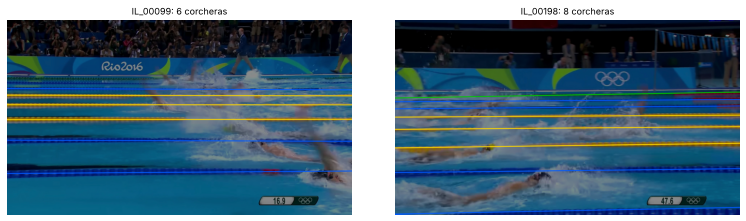

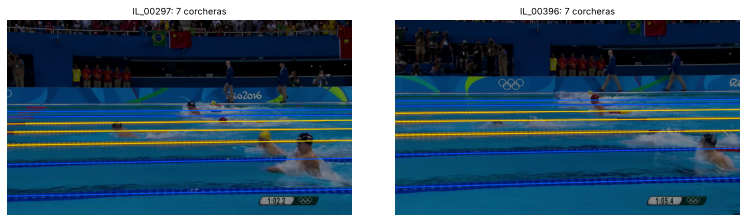

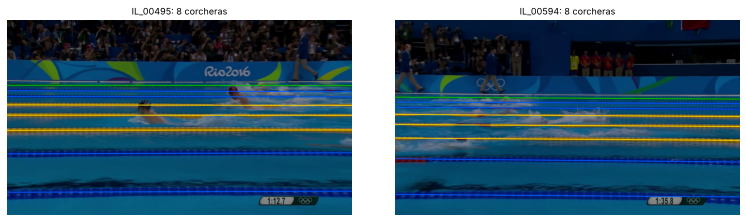

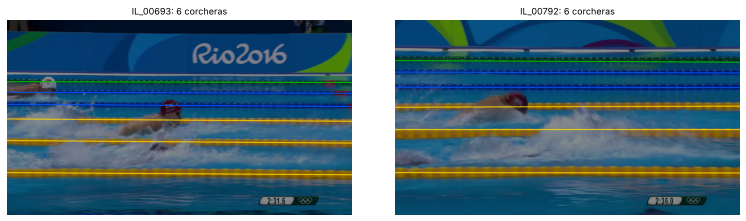

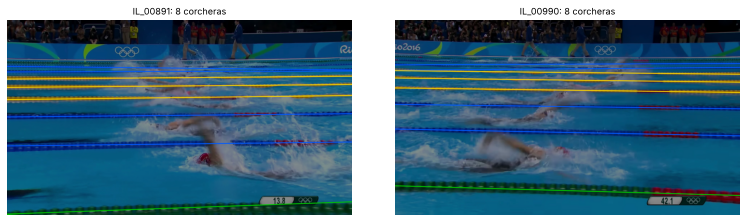

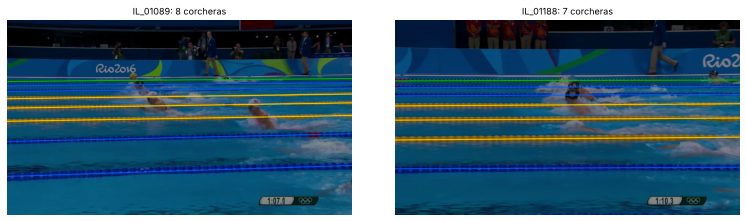

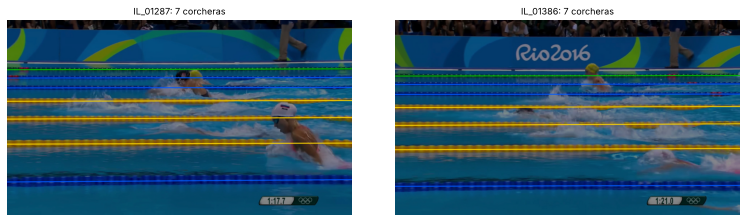

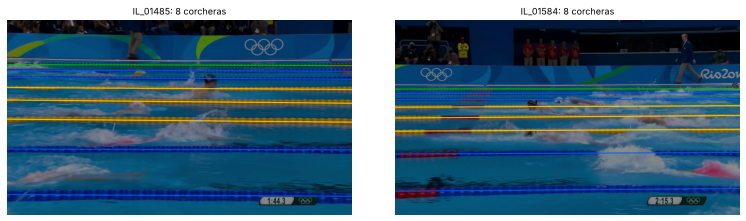

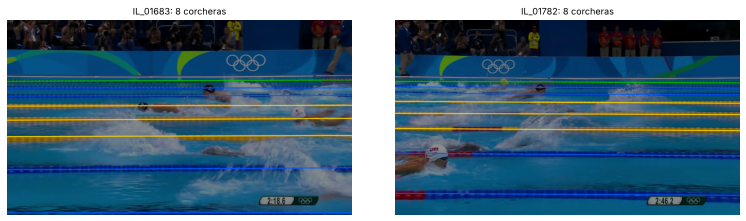

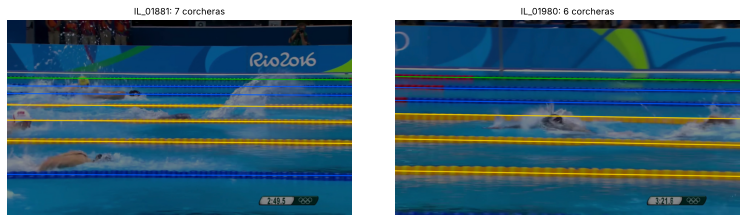

In [15]:
plt.rcParams["figure.dpi"] = 65   # grilla liviana; cada resultado en tamaño completo está en output/piscina/IL
for i in range(0, len(vistas), 2):
    imgs, tits = [], []
    for vis, nombre, n in vistas[i:i + 2]:
        imgs.append(vis)
        tits.append(f"{nombre}: {n} corcheras")
    mostrar(imgs, tits, cols=2, alto=3.4)

## 10. Observaciones

**Lo que funciona**

* **El borde de la piscina sale en las 20 imágenes** como una única recta: la línea blanca del borde/canaleta es lo único blanco, horizontal y de lado a lado. Eso resuelve el problema de que el cartel tenga el mismo tono que el agua.
* **El Canny limpio deja a Hough solo con corcheras.** Sobre el gris, Hough también encuentra las corcheras (son el borde más fuerte), pero además devuelve rectas del público, del cartel, de la espuma y del reloj. Con la máscara de agua (tono) + la apertura horizontal + el recorte bajo el borde, esas rectas desaparecen: se confirma la intuición inicial (ver la comparación de la sección 5).
* **Resolución angular de 0.1°** fue necesaria: con 1° algunas corcheras no superan el umbral porque, en 1920 px, una inclinación de medio grado reparte los votos en muchas celdas de ρ.
* **Intersecciones en coordenadas homogéneas**: la piscina y cada carril salen de cruzar rectas, y el punto de fuga confirma que en IL las corcheras son casi paralelas.
* **Ruido eliminado**: fuera de la piscina, borde, corcheras y reloj. Al volver a correr el detector sobre la imagen limpia ya casi no aparecen rectas de corchera.

**Limitaciones conocidas**

* **Curvatura del lente**: las corcheras no son perfectamente rectas (IL_00099, IL_01980). Una recta es una aproximación; por eso la franja tiene margen y existe el paso de "restos de corchera".
* **Corcheras lejanas bajo mucha espuma** (IL_00099): si están tapadas en más de la mitad del ancho no alcanzan la cobertura mínima y no se reconocen (ni se borran).
* **El inpainting también rellena lo que está encima de la franja**: si un brazo o una cabeza cruza una corchera, esa parte queda con la textura del agua. Hay que tenerlo en cuenta para la siguiente entrega.

**Para generalizar a las otras vistas** solo cambia `PARAMS`:

* **ISL**: corcheras diagonales → `theta_centro` según la inclinación de la toma y un elemento estructurante orientado en vez de horizontal.
* **IS**: corcheras verticales → `theta_centro = 0°`, apertura vertical; aparecen las cuatro paredes y las intersecciones dan las cuatro esquinas reales.
* **ILP**: la máscara de agua de `segmentar_ilp` y probablemente sin borde superior.